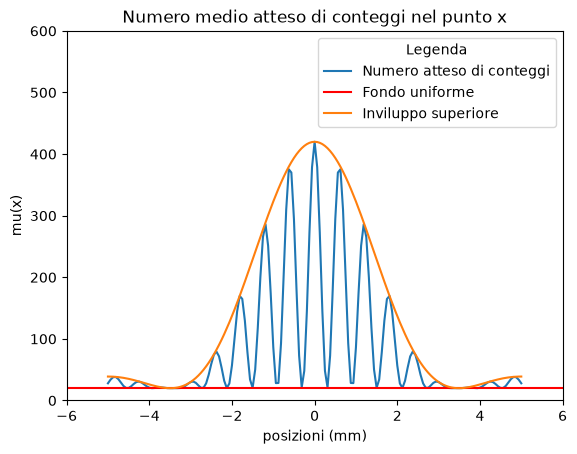

Finita: True, Non negativa: True, Simmetrica: True
mu(0) non è compatibile con B+I_0


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import stats

#STEP1: costruzione del modello

x = np.linspace(-5.0,5.0, 161) #array di posizioni

B = 20 #traslazione sulle y
I_0 = 400 #controlla l'altezza del massimo centrale
alpha = 0.9 #controlla la larghezza del massimo centrale
delta = 5.2 #controlla la distanza tra le frange
E = np.sinc(alpha*x/np.pi)**2
C = np.cos(delta*x)**2
def mu(x): 
    return B+I_0*E*C

#grafico della funzione
fig, ax= plt.subplots()
plt.plot(x, mu(x), label='Numero atteso di conteggi')
plt.axhline(y=B, color="red", label='Fondo uniforme')
def g(x) :
    return B+I_0*E
plt.plot(x, g(x), label='Inviluppo superiore')
plt.xlim(-6.0,6.0)
plt.ylim(0, 600)
ax.set(xlabel="posizioni (mm)", ylabel="mu(x)", title="Numero medio atteso di conteggi nel punto x")
plt.legend(title='Legenda')
plt.show()

#si verifica che la funzione sia finita, non negativa e simmetrica 
inf_o_nan = not np.all(mu(x))
non_negativa = np.all(mu(x)>=0)
simmetrica = np.all(np.isclose(mu(x),mu(-x)))

print(f"Finita: {not inf_o_nan}, Non negativa: {non_negativa}, Simmetrica: {simmetrica}")
if np.any(mu(x=0))!=B+I_0: 
    print ("mu(0) non è compatibile con B+I_0")


Scarto relativo/sigma: 0.41


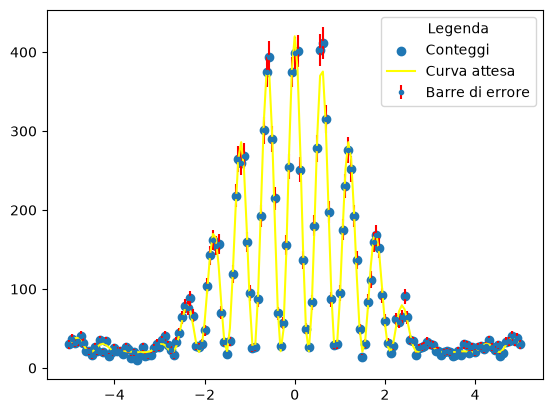

In [ ]:

#STEP 2: simulazione di un'acquisizione

#generazione di un conteggio indipendente per ogni posizione
n_i=np.random.poisson(lam=mu(x))

fig, ax= plt.subplots()
estremi_bin=np.linspace(min(n_i),max(n_i),162)
plt.scatter(x, n_i, label='Conteggi')
n_i_err=np.where(n_i<1, 1, np.sqrt(n_i)) #errore minimo pari a 1
plt.errorbar(x, n_i, yerr= n_i_err, xerr= None, ecolor="red", fmt='.', label='Barre di errore')
plt.plot(x,mu(x), color="yellow", label='Curva attesa')
plt.legend(title='Legenda')

#confronto fra i conteggi  e il valore atteso corrispondente
mask=(x>-1.2) & (x<1.2) #considero la regione centrale
N_c=np.sum(n_i[mask])
valore_atteso=np.sum(mu(x)[mask])
diff=N_c-valore_atteso
sigma=np.sqrt(valore_atteso)
print (f"Scarto relativo/sigma: {diff/sigma:.2f}") 

plt.show()




0.9962780281293018


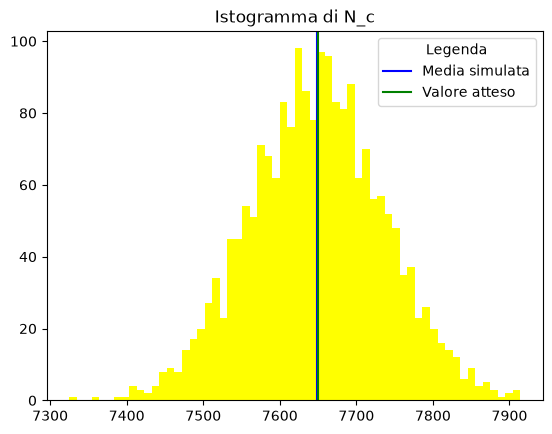

In [3]:
#STEP 3: distribuzione dello stimatore

M=2000 #aumentando il numero degli esperimenti diminuisce l'incertezza associata alla media (err_media)
data_matrix=np.random.poisson(lam=mu(x), size=(M,len(x)))
mask=(x>-1.2) & (x<1.2)
N_c=np.sum(data_matrix[:,mask],axis=1)

mu_c=np.sum(mu(x)[mask])
media= np.mean(N_c)
std=np.std(N_c, ddof=1) #quantità che descrive l'incertezza di una singola acquisizione
err_media=std/np.sqrt(M)
scarto_relativo= np.abs(media -mu_c)/mu_c
sigma_attesa=np.sqrt(mu_c)
confronto=sigma_attesa/std
print(confronto) #rapporto tra sigma_attesa e std confrontabile con 1

plt.hist(N_c, bins=60, color='yellow')
plt.title('Istogramma di N_c')
plt.axvline(x=media, color='blue', label='Media simulata')
plt.axvline(x=mu_c, color='green', label='Valore atteso')
plt.legend(title='Legenda')
plt.show()

#Eliminando il fondo noto B non elimina le fluttuazioni generate dagli eventi di fondo perché eliminare il fondo significa sottrarre un valore costante.